# Visualisierung der Basisdaten

Die zusammengefuehrte Tabelle wird geladen. `slug`, `zeitpunkt` und `status` werden vor der Auswertung entfernt.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

datei = Path("../metadata/basicdata.csv")

data = pd.read_csv(datei, sep=";", encoding="utf-8-sig")
data = data.drop(columns=["slug", "zeitpunkt", "status"], errors="ignore")

data.head()

,Jahr,Monat,Titel,Problem / Aufgabe,Metrik,Kaggle-Link,n_zeilen,n_spalten,n_features,zielspalte,...,ziel_n_unique,aufgabe_vermutet,n_numerisch,n_kategorial,n_fehlende_werte,anteil_fehlend_prozent,spalten_mit_fehlenden,train_mb,sekunden,megabytes
0,2021,1,Tabular Playground Series - Jan 2021,Regression für ein nicht näher spezifiziertes ...,RMSE,https://www.kaggle.com/competitions/tabular-pl...,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
1,2021,2,Tabular Playground Series - Feb 2021,Vorhersage der Höhe eines Versicherungsanspruchs,RMSE,https://www.kaggle.com/competitions/tabular-pl...,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2021,3,Tabular Playground Series - Mar 2021,Binäre Klassifikation: Vorhersage eines Versic...,AUC,https://www.kaggle.com/competitions/tabular-pl...,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2021,4,Tabular Playground Series - Apr 2021,Binäre Klassifikation auf Basis eines Datensat...,Accuracy,https://www.kaggle.com/competitions/tabular-pl...,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2021,5,Tabular Playground Series - May 2021,Multiklassen-Klassifikation: Produktkategorie ...,Multiclass LogLoss,https://www.kaggle.com/competitions/tabular-pl...,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


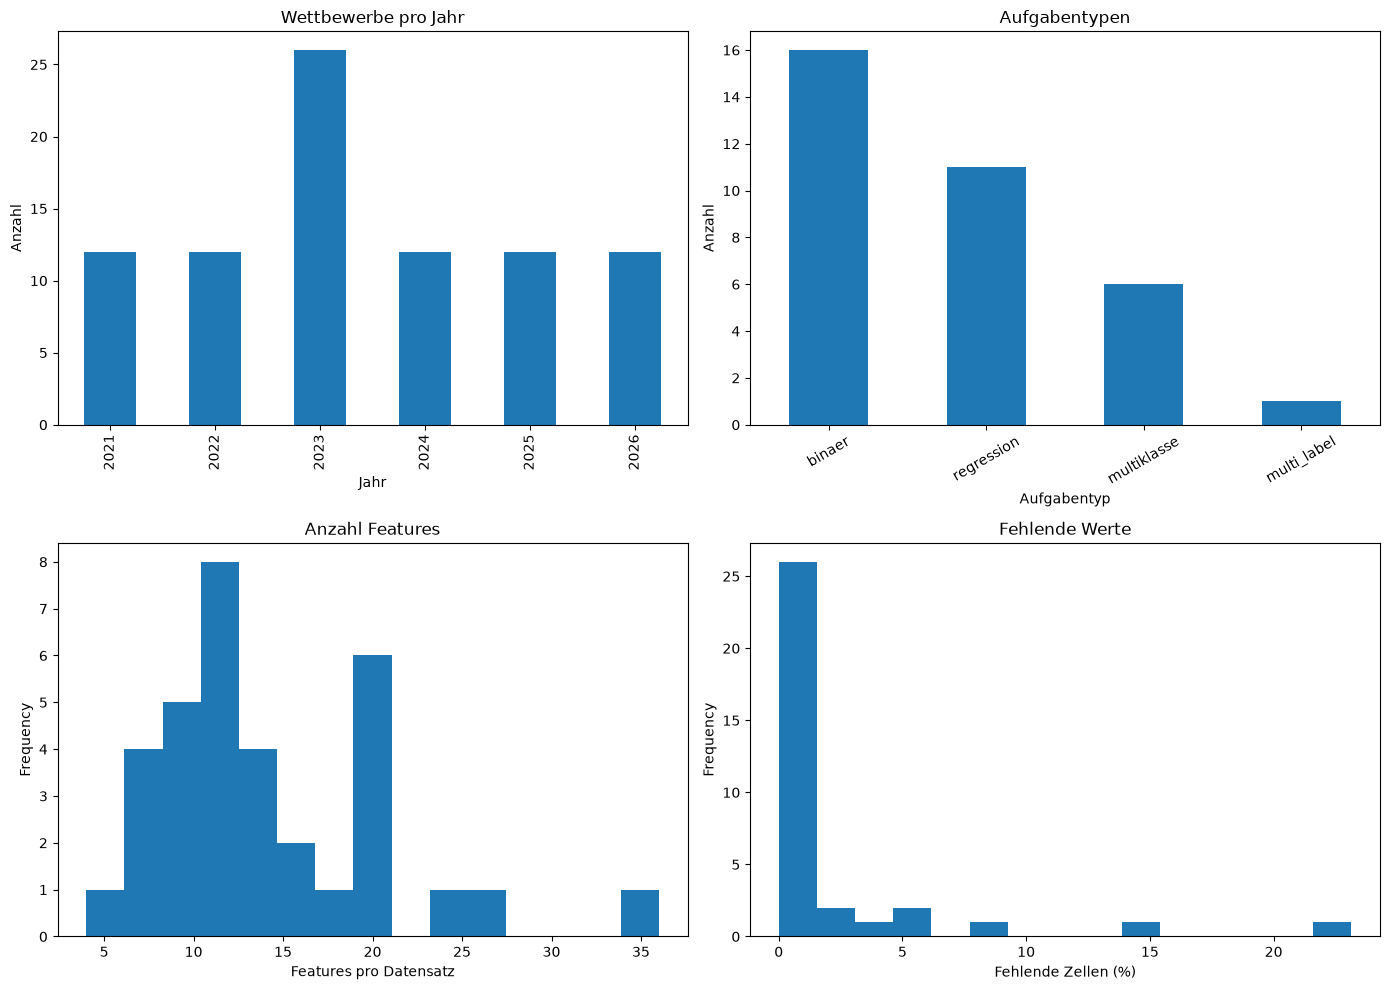

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

data["Jahr"].value_counts().sort_index().plot.bar(ax=axes[0, 0], title="Wettbewerbe pro Jahr")
axes[0, 0].set_xlabel("Jahr")
axes[0, 0].set_ylabel("Anzahl")

data["aufgabe_vermutet"].dropna().value_counts().plot.bar(ax=axes[0, 1], title="Aufgabentypen")
axes[0, 1].set_xlabel("Aufgabentyp")
axes[0, 1].set_ylabel("Anzahl")
axes[0, 1].tick_params(axis="x", rotation=30)

data["n_features"].dropna().plot.hist(bins=15, ax=axes[1, 0], title="Anzahl Features")
axes[1, 0].set_xlabel("Features pro Datensatz")

data["anteil_fehlend_prozent"].dropna().plot.hist(
    bins=15, ax=axes[1, 1], title="Fehlende Werte"
)
axes[1, 1].set_xlabel("Fehlende Zellen (%)")

plt.tight_layout()
plt.show()

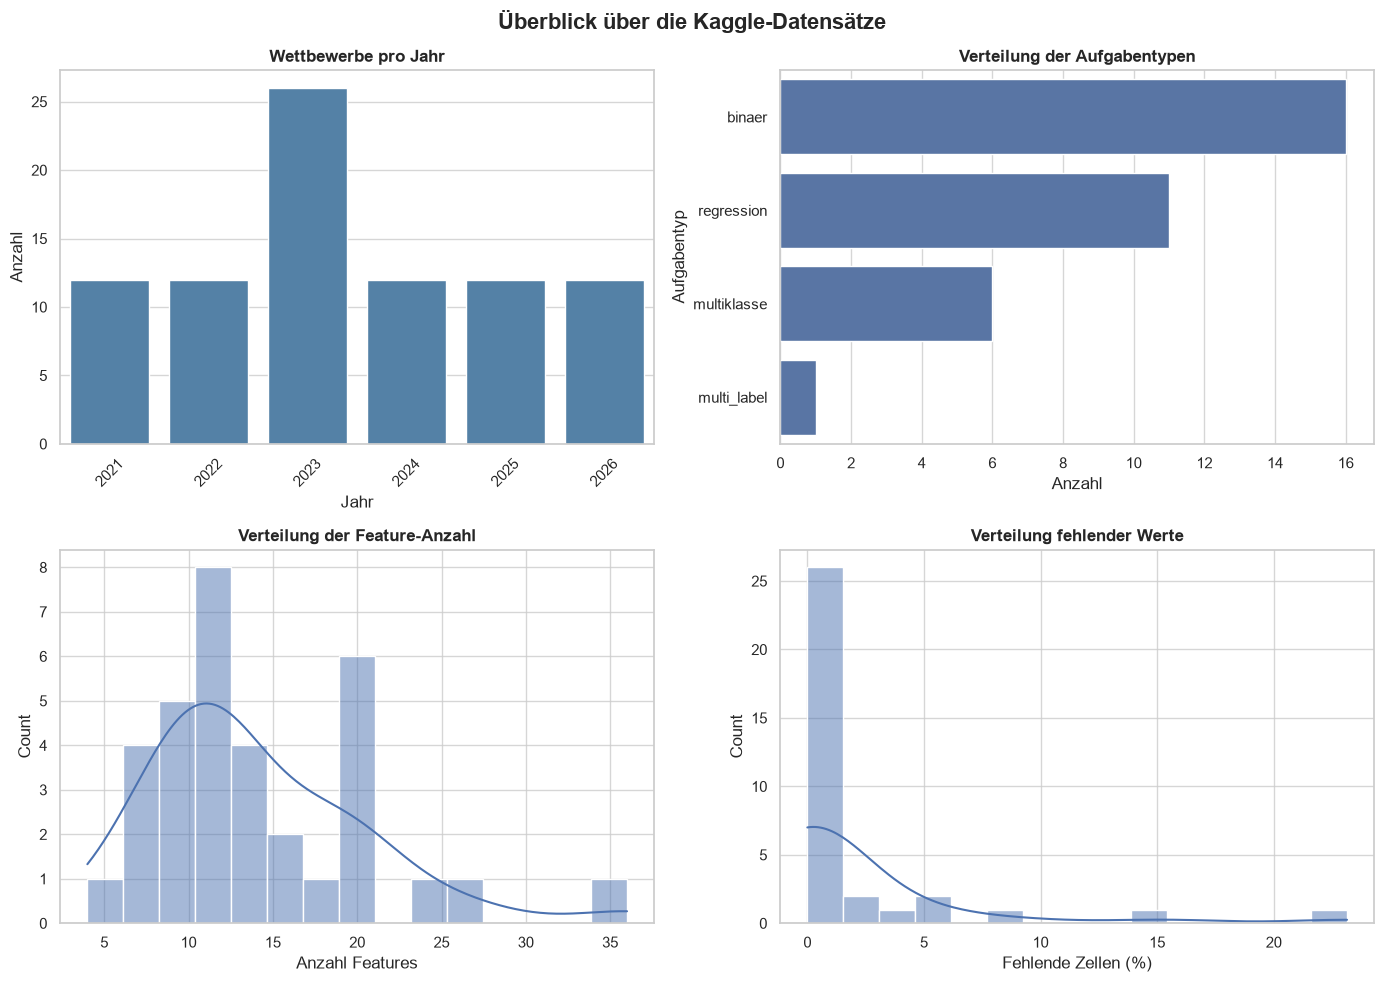

In [ ]:

sns.set_theme(
    style="whitegrid",
    palette="deep",
    context="notebook"
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

fig.suptitle(
    "Überblick über die Kaggle-Datensätze",
    fontsize=16,
    fontweight="bold"
)

# 1. Wettbewerbe pro Jahr
sns.countplot(data=data, x="Jahr", ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Wettbewerbe pro Jahr")
axes[0, 0].set_xlabel("Jahr")
axes[0, 0].set_ylabel("Anzahl")
axes[0, 0].tick_params(axis="x", rotation=45)

# 2. Aufgabentypen
sns.countplot(
    data=data, y="aufgabe_vermutet",
    order=data["aufgabe_vermutet"].value_counts().index,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Verteilung der Aufgabentypen")
axes[0, 1].set_xlabel("Anzahl")
axes[0, 1].set_ylabel("Aufgabentyp")

# 3. Anzahl Features
sns.histplot(data=data, x="n_features", bins=15, kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Verteilung der Feature-Anzahl")
axes[1, 0].set_xlabel("Anzahl Features")

# 4. Fehlende Werte
sns.histplot(
    data=data, x="anteil_fehlend_prozent",
    bins=15, kde=True, ax=axes[1, 1]
)
axes[1, 1].set_title("Verteilung fehlender Werte")
axes[1, 1].set_xlabel("Fehlende Zellen (%)")

plt.tight_layout()
plt.show()
